# 04 – Modèle LSTM et comparaison avec LightGBM

LightGBM ne voit qu'une ligne à la fois : on a dû lui fabriquer à la main des moyennes, écarts-types et pentes glissants. Le LSTM, lui, lit directement la séquence des 30 derniers cycles et apprend seul quels motifs annoncent la panne.

**Question à laquelle on veut répondre :** le LSTM détecte-t-il plus tôt le début de la dégradation (tranche 50-100 cycles, où LightGBM est en retard) ?

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

from src.data.load import PROJECT_ROOT
from src.data.windows import make_windows
from src.features.preprocess import FEATURES_FD001
from src.features.rolling import add_rolling_features, last_cycle
from src.models.lstm import LSTMRegressor, train_lstm, predict_lstm, set_seed
from src.models.metrics import rmse, nasa_score

sns.set_theme(style="whitegrid")
PROC = PROJECT_ROOT / "data" / "processed"
WINDOW = 30
set_seed(42)
print("GPU disponible :", torch.cuda.is_available())

GPU disponible : False


## 1. Fenêtres temporelles

Pour chaque ligne (moteur, cycle t), on construit la matrice des 30 derniers cycles × 14 capteurs. En début de vie (t < 30), on complète en répétant le premier cycle. Les entrées sont les capteurs déjà normalisés à l'étape 2.

In [2]:
sets = {k: pd.read_csv(PROC / f"FD001_{k}.csv") for k in ["train", "calib", "val", "test"]}
W = {k: make_windows(v, FEATURES_FD001, window=WINDOW) for k, v in sets.items()}
for k, (X, y, meta) in W.items():
    print(f"{k:<6}: X {X.shape}  y {y.shape}")

train : X (14407, 30, 14)  y (14407,)
calib : X (3160, 30, 14)  y (3160,)
val   : X (3064, 30, 14)  y (3064,)
test  : X (13096, 30, 14)  y (13096,)


## 2. Entraînement

- Architecture : 2 couches LSTM de 64 neurones, puis une couche dense de 32 neurones
- Perte : erreur quadratique (MSE) sur la RUL divisée par 125
- Optimiseur Adam, taux d'apprentissage divisé par 2 quand la validation stagne
- Arrêt anticipé : on s'arrête après 10 époques sans amélioration et on garde la meilleure

Sur CPU, compter quelques minutes.

In [3]:
Xtr, ytr, _ = W["train"]
Xva, yva, _ = W["val"]
model = LSTMRegressor(n_features=len(FEATURES_FD001), hidden=64, num_layers=2, dropout=0.2)
print("Nombre de paramètres :", sum(p.numel() for p in model.parameters()))
model, hist = train_lstm(model, Xtr, ytr, Xva, yva, epochs=100, batch_size=256, lr=1e-3, patience=10)

Nombre de paramètres : 55873
époque   1 | RMSE train  55.70 | RMSE val  20.14 |     2s
époque   5 | RMSE train  20.39 | RMSE val  16.12 |    15s
époque  10 | RMSE train  18.24 | RMSE val  15.66 |    33s
époque  15 | RMSE train  16.59 | RMSE val  14.99 |    51s
époque  20 | RMSE train  15.57 | RMSE val  14.59 |    64s
époque  25 | RMSE train  14.71 | RMSE val  14.78 |    77s
Arrêt anticipé à l'époque 27 (meilleure val RMSE = 14.02)


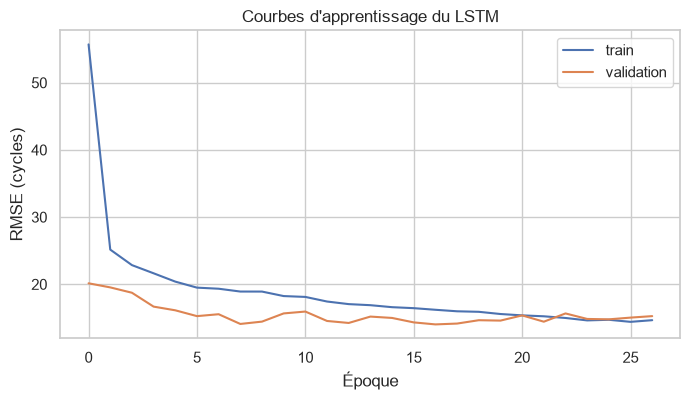

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist["train_rmse"], label="train")
ax.plot(hist["val_rmse"], label="validation")
ax.set(xlabel="Époque", ylabel="RMSE (cycles)", title="Courbes d'apprentissage du LSTM")
ax.legend()
plt.show()

## 3. Prédictions des deux modèles

On recharge le modèle LightGBM de l'étape 3 pour comparer sur exactement les mêmes lignes.

In [5]:
lgb_bundle = joblib.load(PROJECT_ROOT / "models" / "lgbm_fd001.joblib")
lgbm, LGB_FEATS = lgb_bundle["model"], lgb_bundle["features"]

preds = {}
for k in ["val", "test"]:
    X, y, meta = W[k]
    df = meta.copy()
    df["RUL"] = y
    df["LSTM"] = predict_lstm(model, X)
    feats = add_rolling_features(sets[k], FEATURES_FD001, windows=(5, 10, 20))
    feats["LightGBM"] = np.clip(lgbm.predict(feats[LGB_FEATS]), 0, None)
    df = df.merge(feats[["unit", "cycle", "LightGBM"]], on=["unit", "cycle"])
    preds[k] = df

## 4. Comparaison globale

Rappel : le « dernier cycle » de validation est un cas trivial (RUL = 0). Le chiffre qui compte pour se comparer à la littérature est le RMSE au dernier cycle **sur le test**.

In [6]:
rows = {}
for m in ["LightGBM", "LSTM"]:
    v, t = preds["val"], preds["test"]
    tl = last_cycle(t)
    rows[m] = {
        "RMSE val (toutes lignes)": rmse(v.RUL, v[m]),
        "RMSE test (toutes lignes)": rmse(t.RUL, t[m]),
        "RMSE test (dernier cycle)": rmse(tl.RUL, tl[m]),
        "Score NASA test (dernier cycle)": nasa_score(tl.RUL, tl[m]),
    }
comparaison = pd.DataFrame(rows).round(2)
comparaison

,LightGBM,LSTM
RMSE val (toutes lignes),13.83,14.02
RMSE test (toutes lignes),13.86,14.45
RMSE test (dernier cycle),13.53,15.74
Score NASA test (dernier cycle),308.23,498.75


## 5. Comparaison par tranche de RUL

C'est ici qu'on répond à la question de départ : le LSTM corrige-t-il le retard de LightGBM entre 50 et 100 cycles ?

          RMSE          biais         
modèle    LSTM LightGBM  LSTM LightGBM
tranche                               
0-25      4.90     3.92  2.27     1.97
25-50    12.89    13.02  5.38     7.26
50-75    17.29    19.88  5.96    10.65
75-100   18.70    16.86  9.90     7.85
100-125  13.63    13.01 -6.76    -6.19


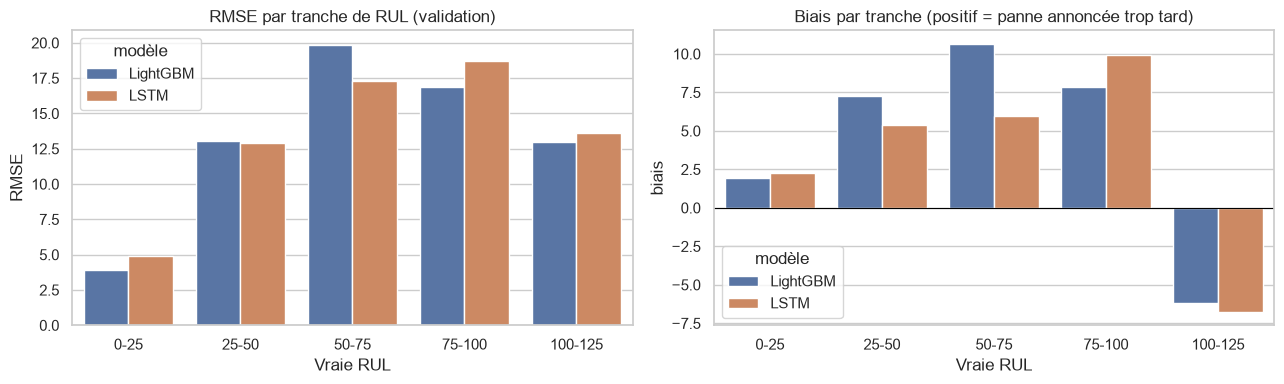

In [7]:
v = preds["val"].copy()
v["tranche"] = pd.cut(v.RUL, bins=[-1, 25, 50, 75, 100, 125], labels=["0-25", "25-50", "50-75", "75-100", "100-125"])
recap = []
for m in ["LightGBM", "LSTM"]:
    e = v[m] - v.RUL
    g = e.groupby(v.tranche, observed=True)
    recap.append(pd.DataFrame({"modèle": m, "RMSE": g.apply(lambda x: np.sqrt((x**2).mean())), "biais": g.mean()}))
recap = pd.concat(recap).reset_index()
print(recap.pivot(index="tranche", columns="modèle", values=["RMSE", "biais"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=recap, x="tranche", y="RMSE", hue="modèle", ax=axes[0])
axes[0].set(title="RMSE par tranche de RUL (validation)", xlabel="Vraie RUL")
sns.barplot(data=recap, x="tranche", y="biais", hue="modèle", ax=axes[1])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(title="Biais par tranche (positif = panne annoncée trop tard)", xlabel="Vraie RUL")
plt.tight_layout()
plt.show()

## 6. Moteur par moteur

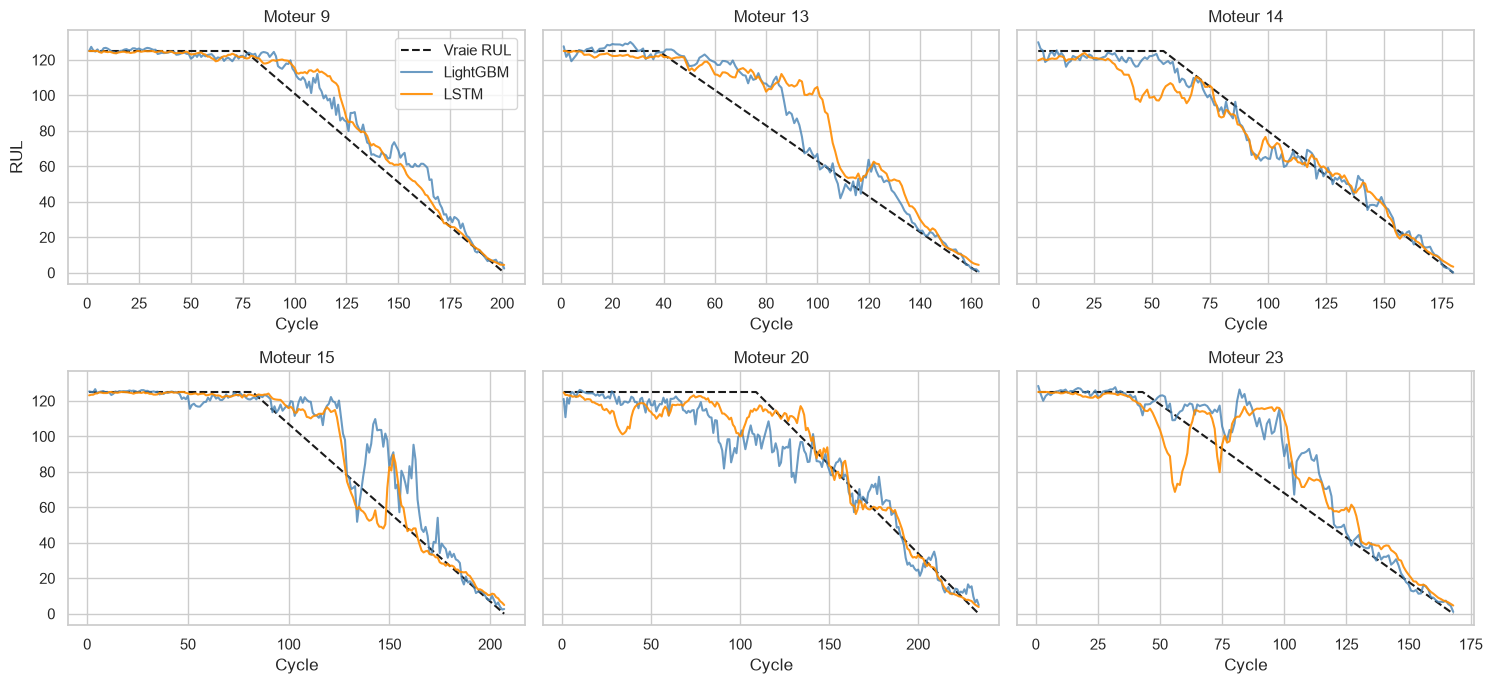

In [8]:
units = v.unit.unique()[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, u in zip(axes.flat, units):
    d = v[v.unit == u]
    ax.plot(d.cycle, d.RUL, "k--", label="Vraie RUL")
    ax.plot(d.cycle, d.LightGBM, color="steelblue", alpha=0.8, label="LightGBM")
    ax.plot(d.cycle, d.LSTM, color="darkorange", alpha=0.9, label="LSTM")
    ax.set(title=f"Moteur {u}", xlabel="Cycle")
axes[0, 0].set_ylabel("RUL")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## 7. Moyenne des deux modèles

Quand deux modèles différents font des erreurs différentes, leur moyenne est souvent meilleure que chacun d'eux.

In [9]:
for k in ["val", "test"]:
    preds[k]["Moyenne"] = (preds[k]["LightGBM"] + preds[k]["LSTM"]) / 2
t, tl = preds["test"], last_cycle(preds["test"])
comparaison["Moyenne"] = [rmse(preds["val"].RUL, preds["val"].Moyenne), rmse(t.RUL, t.Moyenne),
                           rmse(tl.RUL, tl.Moyenne), nasa_score(tl.RUL, tl.Moyenne)]
comparaison.round(2)

,LightGBM,LSTM,Moyenne
RMSE val (toutes lignes),13.83,14.02,12.95
RMSE test (toutes lignes),13.86,14.45,12.93
RMSE test (dernier cycle),13.53,15.74,13.77
Score NASA test (dernier cycle),308.23,498.75,328.22


## 8. Sauvegarde

In [10]:
torch.save({"state_dict": model.state_dict(), "window": WINDOW, "features": FEATURES_FD001,
            "hidden": 64, "num_layers": 2, "dropout": 0.2},
           PROJECT_ROOT / "models" / "lstm_fd001.pt")
print("Modèle sauvegardé")

Modèle sauvegardé


## 9. Conclusions

- **LSTM** (2 couches de 64, fenêtres de 30 cycles, ~56 000 paramètres) : arrêt anticipé à l'époque 27, pas de surapprentissage. Environ 1 minute 20 d'entraînement sur CPU.
- **Test au dernier cycle** : LSTM 15,74 contre LightGBM 13,53 ; score NASA 499 contre 308 (quelques grosses prédictions trop tardives).
- **Toutes lignes** : les deux modèles sont proches (14,45 contre 13,86).
- **Par tranche** : le LSTM corrige en partie le retard de LightGBM entre 25 et 75 cycles (biais 50-75 : +6,0 contre +10,7), mais il est moins bon près de la panne et entre 75 et 100.
- **Moteur par moteur** : prédictions plus lisses que LightGBM, mais quelques fausses alertes (moteur 23 vers le cycle 55, moteur 14 vers le cycle 45).
- **Moyenne des deux modèles** : meilleur score toutes lignes (12,93 sur le test) → ils ne se trompent pas aux mêmes endroits. Au dernier cycle : 13,77, pas mieux que LightGBM seul.
- **Hypothèse** : le LSTM ne connaît pas l'âge du moteur (3ᵉ feature la plus importante de LightGBM) → testée dans le notebook 04b.